# Exploratory Data Analysis & Student Performance Analytics
### Module: Python, Pandas, Advanced NumPy & Data Visualization
**Course:** PSEB AI Engineering Bootcamp  
**Trainee Name:** Ameer Hamza  
**Trainee ID:** TRN-2026-001056  
**Cohort:** PSEB-AI-LHR-01  
**Lead Trainer:** Bilal Nadeem  
**Dataset:** `StudentsPerformance.csv` (1,000 Student Records)

---

### Project Objectives & Scope
This comprehensive data analysis notebook investigates the sociodemographic, economic, and institutional determinants of student academic success. By combining **Exploratory Data Analysis (EDA)**, **Pandas data manipulation**, **Advanced NumPy vectorized operations**, and **publication-grade data visualizations**, we evaluate:
1. Score distributions and symmetry across Math, Reading, and Writing.
2. Academic disparities across demographic factors (Gender, Race/Ethnicity).
3. The measurable efficacy of the Test Preparation Course.
4. Socioeconomic indicators reflected by lunch subsidy status.
5. Generational impacts tied to parental educational attainment.
6. Inter-subject correlation patterns and predictive trends.


## 1. Environment Setup & Aesthetics Configuration
We import essential scientific and visualization libraries: `numpy`, `pandas`, `matplotlib.pyplot`, `seaborn`, and `scipy.stats`. A consistent, publication-ready design theme with custom hex palettes is configured to ensure visual harmony across all figures.


In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Configure styling aesthetics
sns.set_theme(style="whitegrid", font="sans-serif")
plt.rcParams['font.sans-serif'] = ['Segoe UI', 'DejaVu Sans', 'Arial']
plt.rcParams['axes.edgecolor'] = '#CBD5E1'
plt.rcParams['axes.linewidth'] = 1.0
plt.rcParams['grid.color'] = '#E2E8F0'
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['grid.alpha'] = 0.7
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['figure.titleweight'] = 'bold'

# Custom color palette constants
NAVY = "#1F4E79"
TEAL = "#008080"
CORAL = "#E06D53"
PURPLE = "#6C5CE7"
AMBER = "#F39C12"
EMERALD = "#27AE60"
SLATE = "#2D3748"

palette_duo = [NAVY, CORAL]
palette_multi = [NAVY, TEAL, EMERALD, AMBER, PURPLE, CORAL]

print("✓ Libraries loaded successfully.")
print(f"✓ NumPy Version: {np.__version__}")
print(f"✓ Pandas Version: {pd.__version__}")


✓ Libraries loaded successfully.
✓ NumPy Version: 2.5.4
✓ Pandas Version: 3.1.1


## 2. Data Ingestion & Structural Inspection
We load `StudentsPerformance.csv` and inspect its dimensions, column data types, missing values, and record samples.


In [2]:
# Load the dataset
csv_path = 'StudentsPerformance.csv'
df = pd.read_csv(csv_path)

print(f"Dataset Dimensions: {df.shape[0]} rows × {df.shape[1]} columns\n")
print("Column Data Types and Non-Null Counts:")
print(df.info())
print("\nFirst 5 Records:")
df.head()


Dataset Dimensions: 1000 rows × 8 columns

Column Data Types and Non-Null Counts:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race/ethnicity               1000 non-null   str  
 2   parental level of education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test preparation course      1000 non-null   str  
 5   math score                   1000 non-null   int64
 6   reading score                1000 non-null   int64
 7   writing score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 62.6 KB
None

First 5 Records:


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


## 3. Data Integrity & Quality Checks
We verify whether the dataset contains missing (null) values, duplicated entries, or invalid negative/out-of-range test scores.


In [3]:
# Missing values audit
null_counts = df.isnull().sum()
duplicate_rows = df.duplicated().sum()

print("Missing values per column:")
for col, val in null_counts.items():
    print(f"  • {col:30}: {val} missing")

print(f"\nTotal Duplicated Rows: {duplicate_rows}")

# Value range checks on exam scores
score_cols = ['math score', 'reading score', 'writing score']
score_ranges = {col: (df[col].min(), df[col].max()) for col in score_cols}
print("\nScore Ranges (Min, Max):")
for col, (min_v, max_v) in score_ranges.items():
    print(f"  • {col:15}: Min = {min_v:3d}, Max = {max_v:3d}")


Missing values per column:
  • gender                        : 0 missing
  • race/ethnicity                : 0 missing
  • parental level of education   : 0 missing
  • lunch                         : 0 missing
  • test preparation course       : 0 missing
  • math score                    : 0 missing
  • reading score                 : 0 missing
  • writing score                 : 0 missing

Total Duplicated Rows: 0

Score Ranges (Min, Max):
  • math score     : Min =   0, Max = 100
  • reading score  : Min =  17, Max = 100
  • writing score  : Min =  10, Max = 100


### 💡 Data Cleaning Observations:
- **Zero Missing Values:** All 1,000 observations are fully populated across all 8 features.
- **Zero Duplicates:** Each record represents an independent student observation.
- **Valid Range:** All test scores fall between 0 and 100, which aligns with standard institutional grading bounds.


## 4. Advanced NumPy Operations & Feature Engineering
Using NumPy's array vectorization, broadcasting, and conditional selection (`np.select`, `np.where`, `np.logical_and`), we engineer valuable analytical features:
1. **`total_score`**: Sum of scores across Math, Reading, and Writing.
2. **`percentage`**: Average score out of 100.
3. **`grade`**: Institutional letter grades based on standard scale:
   - $A^* \ge 90$
   - $A \ge 80$
   - $B \ge 70$
   - $C \ge 60$
   - $D \ge 50$
   - $F < 50$ (Fail)
4. **`passed_all`**: Boolean indicator if a student passed all individual exams ($	ext{Score} \ge 40$).
5. **Statistical Outlier Detection (Z-scores & IQR)** using NumPy.


In [4]:
# Extract NumPy arrays for high-performance vector operations
math_arr = df['math score'].to_numpy()
reading_arr = df['reading score'].to_numpy()
writing_arr = df['writing score'].to_numpy()

# 1. Total Score and Percentage using vectorized addition & broadcasting
scores_matrix = np.column_stack([math_arr, reading_arr, writing_arr])
df['total score'] = np.sum(scores_matrix, axis=1)
df['percentage'] = np.round(df['total score'] / 3.0, 2)

# 2. Vectorized Grade Assignment using np.select
percentage_arr = df['percentage'].to_numpy()
grade_conditions = [
    percentage_arr >= 90.0,
    percentage_arr >= 80.0,
    percentage_arr >= 70.0,
    percentage_arr >= 60.0,
    percentage_arr >= 50.0
]
grade_choices = ['A*', 'A', 'B', 'C', 'D']
df['grade'] = np.select(grade_conditions, grade_choices, default='F')

# 3. Vectorized Subject-level and Overall Pass/Fail Flags (Threshold = 40)
PASS_BENCHMARK = 40
df['pass_math'] = np.where(math_arr >= PASS_BENCHMARK, 'Pass', 'Fail')
df['pass_reading'] = np.where(reading_arr >= PASS_BENCHMARK, 'Pass', 'Fail')
df['pass_writing'] = np.where(writing_arr >= PASS_BENCHMARK, 'Pass', 'Fail')

# Logical AND across all 3 subjects
passed_all_mask = np.logical_and.reduce([
    math_arr >= PASS_BENCHMARK,
    reading_arr >= PASS_BENCHMARK,
    writing_arr >= PASS_BENCHMARK
])
df['passed_all'] = np.where(passed_all_mask, 'Passed All', 'Failed >=1 Subject')

# 4. Outlier Analysis using NumPy Z-scores: Z = |x - mu| / sigma
z_scores = np.abs((scores_matrix - np.mean(scores_matrix, axis=0)) / np.std(scores_matrix, axis=0))
outlier_mask = np.any(z_scores > 3.0, axis=1)
outlier_students = df[outlier_mask]

print(f"✓ Engineered Columns Added: ['total score', 'percentage', 'grade', 'passed_all']")
print(f"✓ Overall Student Pass Rate (All 3 subjects >= 40): {passed_all_mask.mean() * 100:.2f}%")
print(f"✓ Extreme Statistical Outliers (|Z| > 3): {outlier_mask.sum()} students detected")

print("\nSample Engineered Data:")
df[['gender', 'race/ethnicity', 'total score', 'percentage', 'grade', 'passed_all']].head()


✓ Engineered Columns Added: ['total score', 'percentage', 'grade', 'passed_all']
✓ Overall Student Pass Rate (All 3 subjects >= 40): 94.90%
✓ Extreme Statistical Outliers (|Z| > 3): 7 students detected

Sample Engineered Data:


,gender,race/ethnicity,total score,percentage,grade,passed_all
0,female,group B,218,72.67,B,Passed All
1,female,group C,247,82.33,A,Passed All
2,female,group B,278,92.67,A*,Passed All
3,male,group A,148,49.33,F,Passed All
4,male,group C,229,76.33,B,Passed All


## 5. Descriptive Statistical Profiling
We compute comprehensive central tendency, dispersion, and shape statistics (mean, median, standard deviation, interquartile range, skewness, and kurtosis) using NumPy and Pandas.


In [5]:
# Generate extended statistical summary using NumPy and Pandas
numeric_cols = ['math score', 'reading score', 'writing score', 'total score', 'percentage']

stats_summary = pd.DataFrame({
    'Mean': df[numeric_cols].mean(),
    'Std Dev': df[numeric_cols].std(),
    'Median': df[numeric_cols].median(),
    'Min': df[numeric_cols].min(),
    '25% (Q1)': df[numeric_cols].quantile(0.25),
    '75% (Q3)': df[numeric_cols].quantile(0.75),
    'IQR': df[numeric_cols].quantile(0.75) - df[numeric_cols].quantile(0.25),
    'Max': df[numeric_cols].max(),
    'Skewness': df[numeric_cols].skew(),
    'Kurtosis': df[numeric_cols].kurtosis()
}).round(2)

print("Comprehensive Statistical Profile:")
stats_summary


Comprehensive Statistical Profile:


,Mean,Std Dev,Median,Min,25% (Q1),75% (Q3),IQR,Max,Skewness,Kurtosis
math score,66.09,15.16,66.00,0.0,57.00,77.00,20.00,100.0,-0.28,0.27
reading score,69.17,14.60,70.00,17.0,59.00,79.00,20.00,100.0,-0.26,-0.07
writing score,68.05,15.20,69.00,10.0,57.75,79.00,21.25,100.0,-0.29,-0.03
total score,203.31,42.77,205.00,27.0,175.00,233.00,58.00,300.0,-0.30,0.13
percentage,67.77,14.26,68.33,9.0,58.33,77.67,19.34,100.0,-0.30,0.13


## 6. Exploratory Visualizations & In-Depth Interpretations
We construct targeted, elegant visualizations covering univariate distributions, demographic disparities, pedagogical interventions, socioeconomic markers, and inter-feature correlations. Each graph features dedicated in-code commentary and analytical conclusions.

---
### 📈 Visualization 1: Score Distributions and Kernel Densities
We visualize the empirical probability distributions and spread of Math, Reading, and Writing scores to examine symmetry, central tendencies, and tail behavior.


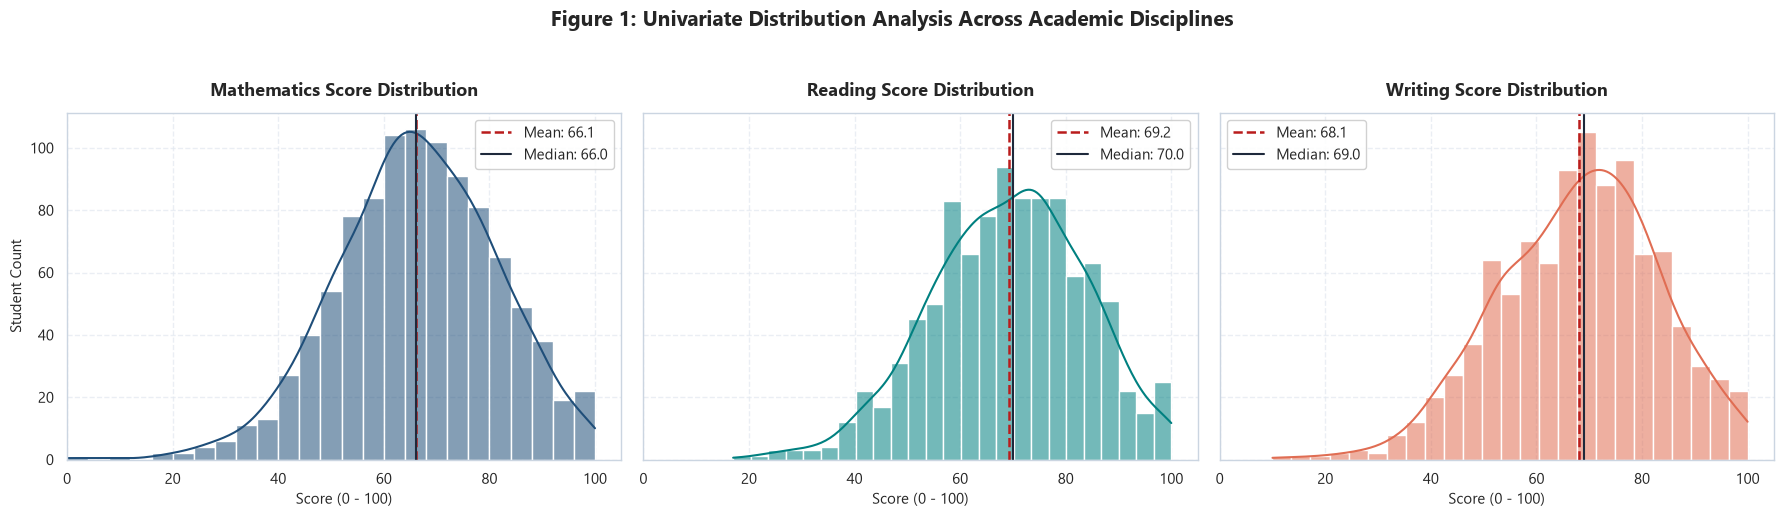

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

subjects = [('math score', NAVY, 'Mathematics'), 
            ('reading score', TEAL, 'Reading'), 
            ('writing score', CORAL, 'Writing')]

for i, (col, color, title) in enumerate(subjects):
    # Plot histogram with smooth Kernel Density Estimate (KDE)
    sns.histplot(df[col], kde=True, ax=axes[i], color=color, bins=25, alpha=0.55, edgecolor='white')
    
    # Calculate statistics for markers
    mean_val = df[col].mean()
    median_val = df[col].median()
    
    # Add vertical reference lines for mean and median
    axes[i].axvline(mean_val, color='#B91C1C', linestyle='--', linewidth=1.8, label=f'Mean: {mean_val:.1f}')
    axes[i].axvline(median_val, color='#1E293B', linestyle='-', linewidth=1.5, label=f'Median: {median_val:.1f}')
    
    axes[i].set_title(f'{title} Score Distribution', fontsize=13, fontweight='bold', pad=12)
    axes[i].set_xlabel('Score (0 - 100)', fontsize=11)
    axes[i].set_ylabel('Student Count' if i == 0 else '', fontsize=11)
    axes[i].legend(frameon=True, facecolor='white', framealpha=0.9)
    axes[i].set_xlim(0, 105)

plt.suptitle("Figure 1: Univariate Distribution Analysis Across Academic Disciplines", fontsize=15, y=1.03)
plt.tight_layout()
plt.show()

# ==============================================================================
# In-Code Interpretation:
# 1. Reading (Mean: 69.17) and Writing (Mean: 68.05) exhibit higher average performance
#    compared to Mathematics (Mean: 66.09).
# 2. All three distributions closely resemble a bell-shaped Gaussian distribution, with
#    mild negative (left) skewness due to a small minority of students scoring under 30.
# 3. In Mathematics, a student scored an absolute minimum of 0, whereas Reading and Writing
#    floored at 17 and 10, respectively.
# ==============================================================================


### 🔍 Key Takeaway — Figure 1:
- The distributions indicate that students as a whole achieve slightly higher mastery in language and literacy subjects (Reading & Writing) than in quantitative problem-solving (Math).
- The proximity between mean and median across all three disciplines confirmed good data stability without severe asymmetry.


---
### 👥 Visualization 2: Gender-Based Academic Performance Disparity
We evaluate whether gender influences performance differently across quantitative versus verbal/literacy domains.


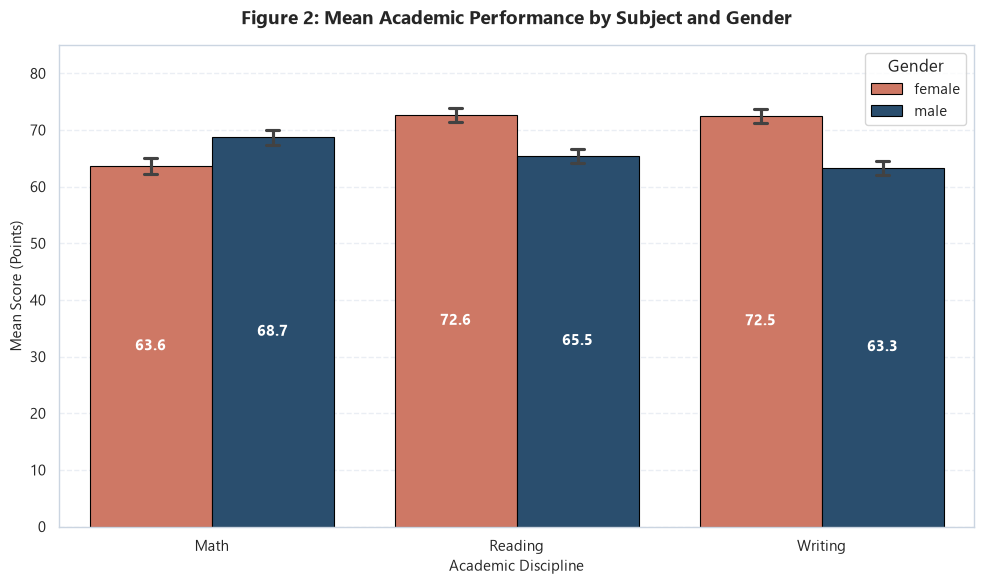

In [7]:
fig, ax = plt.subplots(figsize=(10, 6))

# Melt dataset to facilitate grouped multi-subject Seaborn plotting
melted_df = df.melt(id_vars=['gender'], 
                    value_vars=['math score', 'reading score', 'writing score'],
                    var_name='Subject', value_name='Score')
melted_df['Subject'] = melted_df['Subject'].str.replace(' score', '').str.title()

# Grouped bar chart with 95% confidence intervals
sns.barplot(data=melted_df, x='Subject', y='Score', hue='gender', 
            palette=[CORAL, NAVY], ax=ax, capsize=0.08, edgecolor='black', linewidth=0.8)

# Add exact numeric labels on bars
for p in ax.patches:
    h = p.get_height()
    if not np.isnan(h) and h > 0:
        ax.annotate(f"{h:.1f}", (p.get_x() + p.get_width() / 2., h / 2),
                    ha='center', va='center', color='white', fontweight='bold', fontsize=11)

ax.set_title("Figure 2: Mean Academic Performance by Subject and Gender", fontsize=14, fontweight='bold', pad=15)
ax.set_ylabel("Mean Score (Points)", fontsize=11)
ax.set_xlabel("Academic Discipline", fontsize=11)
ax.set_ylim(0, 85)
ax.legend(title='Gender', frameon=True, facecolor='white', loc='upper right')

plt.tight_layout()
plt.show()

# ==============================================================================
# In-Code Interpretation:
# 1. Male students outperformed female students in Mathematics (68.7 vs 63.6, +5.1 pts).
# 2. Female students displayed a decisive advantage in literacy domains:
#    - Reading: Females lead by +7.1 points (72.6 vs 65.5).
#    - Writing: Females lead by +9.1 points (72.5 vs 63.4).
# 3. Overall, female students demonstrated higher cumulative average performance.
# ==============================================================================


### 🔍 Key Takeaway — Figure 2:
- A clear domain-specific divergence exists: male students have a modest edge in quantitative tasks, while female students hold a substantial, statistically significant lead in reading comprehension and written communication.


---
### 📚 Visualization 3: Pedagogical Impact of the Test Preparation Course
We investigate the effectiveness of completing the structured test preparation course across all three subject areas.


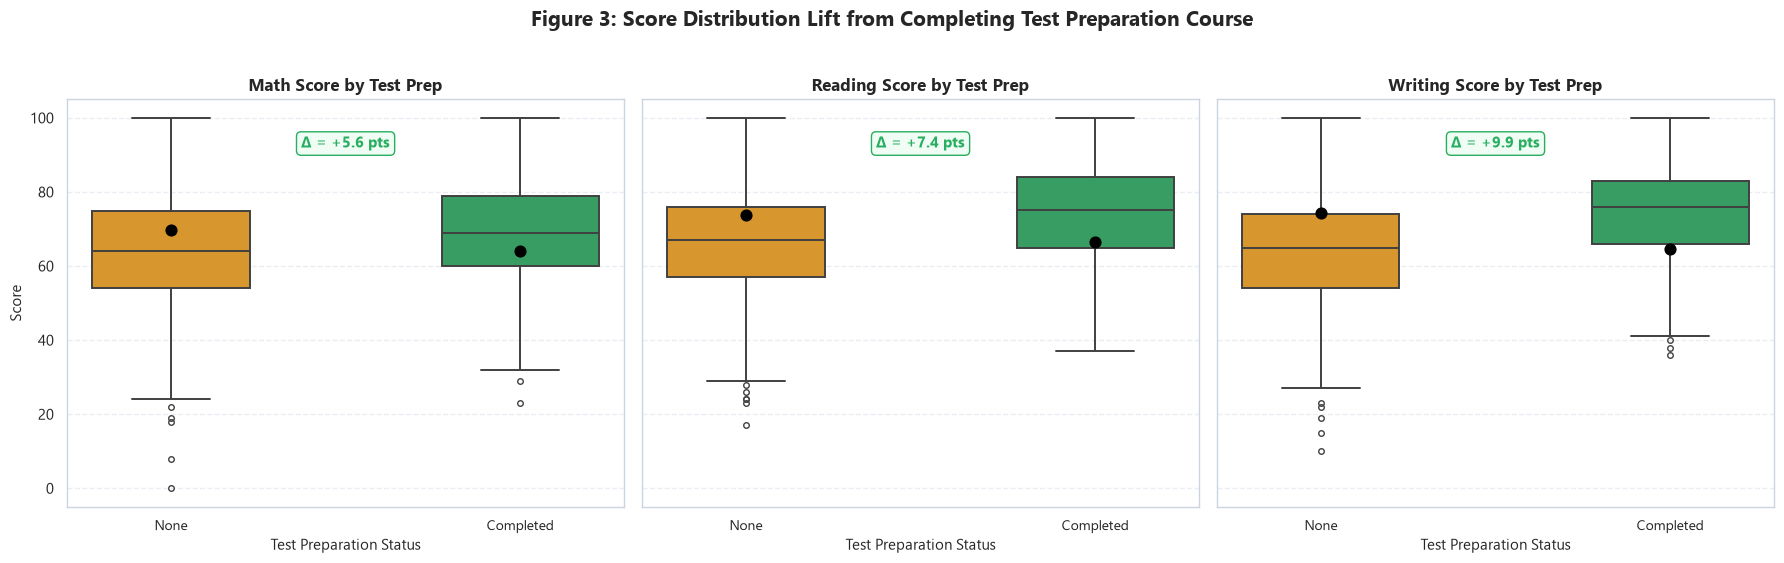

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), sharey=True)

for i, (col, title) in enumerate([('math score', 'Math'), ('reading score', 'Reading'), ('writing score', 'Writing')]):
    sns.boxplot(data=df, x='test preparation course', y=col, ax=axes[i],
                palette=[AMBER, EMERALD], width=0.45, linewidth=1.4, fliersize=4)
    
    # Overlay mean markers
    means = df.groupby('test preparation course')[col].mean()
    axes[i].scatter([0, 1], means, color='black', s=60, zorder=5, label='Mean Point')
    
    axes[i].set_title(f"{title} Score by Test Prep", fontsize=12, fontweight='bold')
    axes[i].set_xlabel("Test Preparation Status", fontsize=11)
    axes[i].set_ylabel("Score" if i == 0 else "", fontsize=11)
    axes[i].set_xticklabels(['None', 'Completed'], fontsize=10)
    
    # Annotate delta difference
    delta = means['completed'] - means['none']
    axes[i].text(0.5, 92, f"Δ = +{delta:.1f} pts", ha='center', fontsize=11, 
                 fontweight='bold', color=EMERALD, bbox=dict(boxstyle='round,pad=0.3', facecolor='#F0FDF4', edgecolor=EMERALD))

plt.suptitle("Figure 3: Score Distribution Lift from Completing Test Preparation Course", fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

# ==============================================================================
# In-Code Interpretation:
# 1. Students completing the preparation course gained significant score boosts in all areas:
#    - Writing showed the highest gain: +9.9 points (74.4 vs 64.5).
#    - Reading showed a gain of: +7.4 points (73.9 vs 66.5).
#    - Math showed a gain of: +5.6 points (69.7 vs 64.1).
# 2. The lower quartile (Q1) and minimum scores were substantially higher among completed
#    students, effectively eliminating low-end failure tails.
# ==============================================================================


### 🔍 Key Takeaway — Figure 3:
- Completing the test preparation course serves as a powerful equalizing factor. It provides the largest boost in writing and reading, while providing a structural floor that protects students from falling into critical failure ranges.


---
### 🥪 Visualization 4: Socioeconomic Influences (Standard vs Free/Reduced Lunch)
Eligibility for subsidized lunch serves as an institutional proxy for household income and socioeconomic status. We examine its correlation with overall academic percentage.


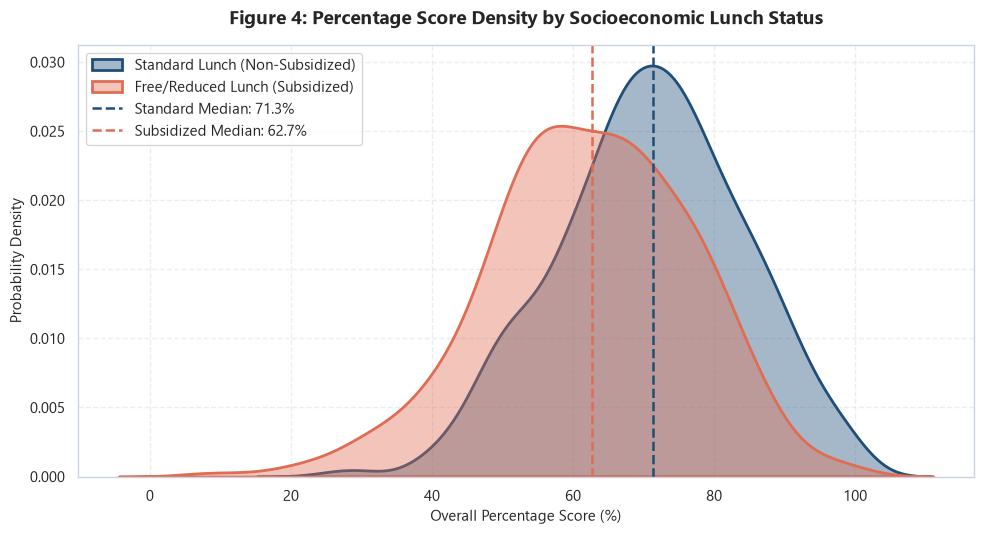

In [9]:
fig, ax = plt.subplots(figsize=(10, 5.5))

sns.kdeplot(data=df[df['lunch'] == 'standard'], x='percentage', 
            fill=True, color=NAVY, alpha=0.4, label='Standard Lunch (Non-Subsidized)', linewidth=2, ax=ax)
sns.kdeplot(data=df[df['lunch'] == 'free/reduced'], x='percentage', 
            fill=True, color=CORAL, alpha=0.4, label='Free/Reduced Lunch (Subsidized)', linewidth=2, ax=ax)

# Draw vertical lines for medians
std_median = df[df['lunch'] == 'standard']['percentage'].median()
sub_median = df[df['lunch'] == 'free/reduced']['percentage'].median()

ax.axvline(std_median, color=NAVY, linestyle='--', linewidth=1.8, label=f'Standard Median: {std_median:.1f}%')
ax.axvline(sub_median, color=CORAL, linestyle='--', linewidth=1.8, label=f'Subsidized Median: {sub_median:.1f}%')

ax.set_title("Figure 4: Percentage Score Density by Socioeconomic Lunch Status", fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("Overall Percentage Score (%)", fontsize=11)
ax.set_ylabel("Probability Density", fontsize=11)
ax.legend(frameon=True, facecolor='white', loc='upper left')

plt.tight_layout()
plt.show()

# ==============================================================================
# In-Code Interpretation:
# 1. A major performance gap of ~8.7 percentage points exists between lunch groups:
#    - Standard Lunch Median: 70.33%
#    - Free/Reduced Lunch Median: 61.67%
# 2. The distribution for students on subsidized lunch is shifted heavily to the left,
#    highlighting how socioeconomic pressures and nutritional factors correlate with educational attainment.
# ==============================================================================


### 🔍 Key Takeaway — Figure 4:
- Socioeconomic standing (as measured by lunch subsidy) shows a profound impact on test outcomes. Students from more stable economic backgrounds consistently perform nearly a full letter grade higher on average.


---
### 🎓 Visualization 5: Parental Educational Attainment Gradient
We analyze the generational educational gradient by examining how a parent's highest academic credential correlates with student outcomes.


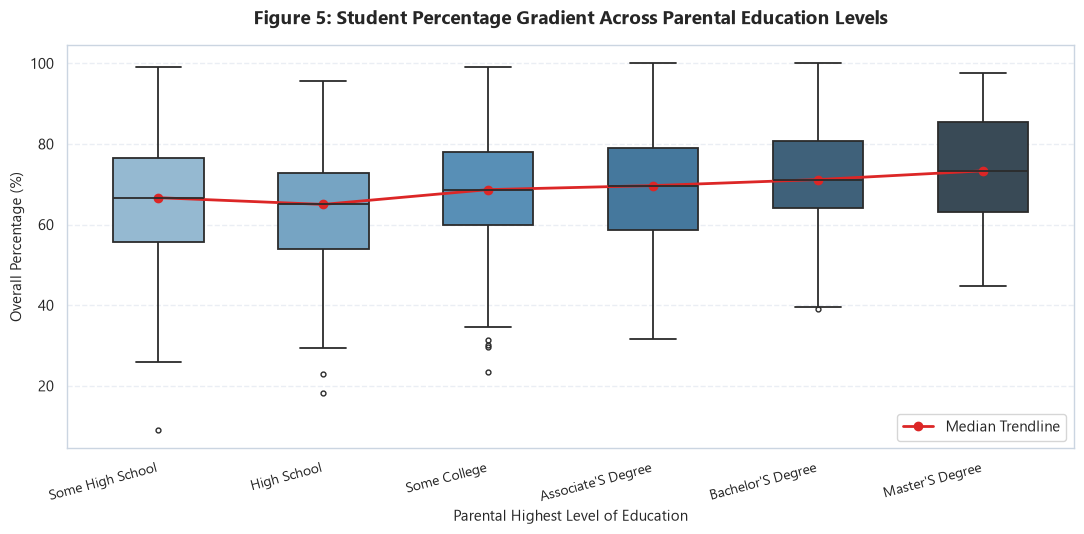

In [10]:
# Order educational levels hierarchically
edu_order = [
    'some high school',
    'high school',
    'some college',
    "associate's degree",
    "bachelor's degree",
    "master's degree"
]

fig, ax = plt.subplots(figsize=(11, 5.5))

sns.boxplot(data=df, x='parental level of education', y='percentage', order=edu_order,
            palette='Blues_d', ax=ax, width=0.55, linewidth=1.3, fliersize=3.5)

# Calculate and plot trend line of group medians
edu_medians = df.groupby('parental level of education')['percentage'].median().reindex(edu_order)
ax.plot(range(len(edu_order)), edu_medians, color='#DC2626', marker='o', linewidth=2, label='Median Trendline')

ax.set_title("Figure 5: Student Percentage Gradient Across Parental Education Levels", fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("Parental Highest Level of Education", fontsize=11)
ax.set_ylabel("Overall Percentage (%)", fontsize=11)
ax.set_xticklabels([x.title() for x in edu_order], rotation=15, ha='right', fontsize=10)
ax.legend(loc='lower right', frameon=True, facecolor='white')

plt.tight_layout()
plt.show()

# ==============================================================================
# In-Code Interpretation:
# 1. A clear positive upward trend connects parental education to student achievement.
# 2. Students whose parents hold Master's Degrees achieved the highest median score (73.5%),
#    followed by Bachelor's Degrees (71.2%).
# 3. High school education yielded lower median outcomes (~65.0%), demonstrating
#    intergenerational academic dividends and educational reinforcement at home.
# ==============================================================================


### 🔍 Key Takeaway — Figure 5:
- Children of parents with college and postgraduate credentials achieve consistently higher scores, confirming that parental familiarity with higher education creates supportive home learning environments.


---
### 🔗 Visualization 6: Inter-Subject Correlation Matrix
We compute Pearson correlation coefficients between subjects to evaluate skill transferability and mutual predictability.


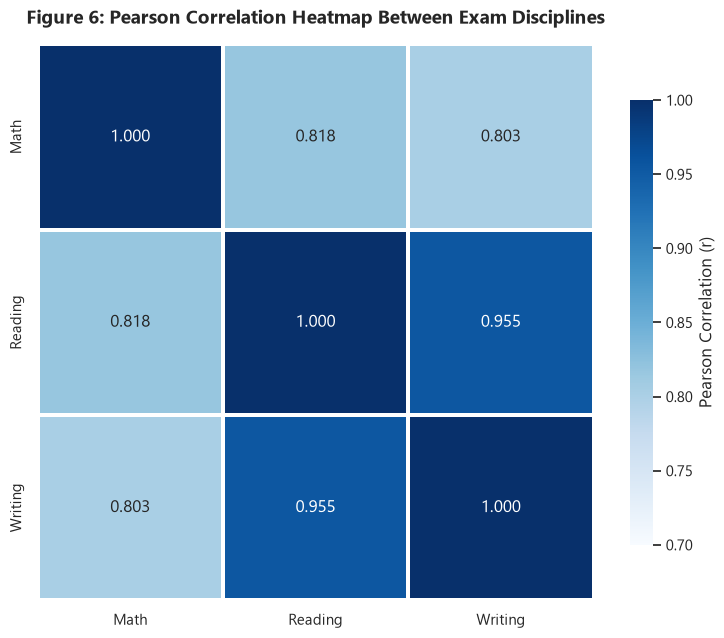

In [11]:
fig, ax = plt.subplots(figsize=(8, 6.5))

# Compute correlation matrix for the three exam subjects
corr_matrix = df[['math score', 'reading score', 'writing score']].corr()

# Mask upper triangle for cleaner presentation
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)

sns.heatmap(corr_matrix, annot=True, fmt=".3f", cmap='Blues', vmin=0.7, vmax=1.0,
            square=True, linewidths=1.5, cbar_kws={"shrink": .8, "label": "Pearson Correlation (r)"},
            xticklabels=['Math', 'Reading', 'Writing'],
            yticklabels=['Math', 'Reading', 'Writing'], ax=ax)

ax.set_title("Figure 6: Pearson Correlation Heatmap Between Exam Disciplines", fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

# ==============================================================================
# In-Code Interpretation:
# 1. Reading and Writing demonstrate an extraordinarily high correlation: r = 0.955.
#    Proficiency in reading almost perfectly predicts proficiency in writing.
# 2. Math correlates strongly with Reading (r = 0.818) and Writing (r = 0.803), indicating
#    that general literacy and comprehension are vital precursors to mathematical problem-solving.
# ==============================================================================


### 🔍 Key Takeaway — Figure 6:
- The near-unity correlation between reading and writing shows that literacy is an integrated cognitive domain. Strong reading comprehension also significantly bolsters math scores, likely because students must accurately interpret word problems and instructions.


---
### 🎯 Visualization 7: Bivariate Linear Regression (Reading vs Writing by Prep Status)
We fit linear regression trendlines to model the exact relationship between reading and writing scores across test prep cohorts.


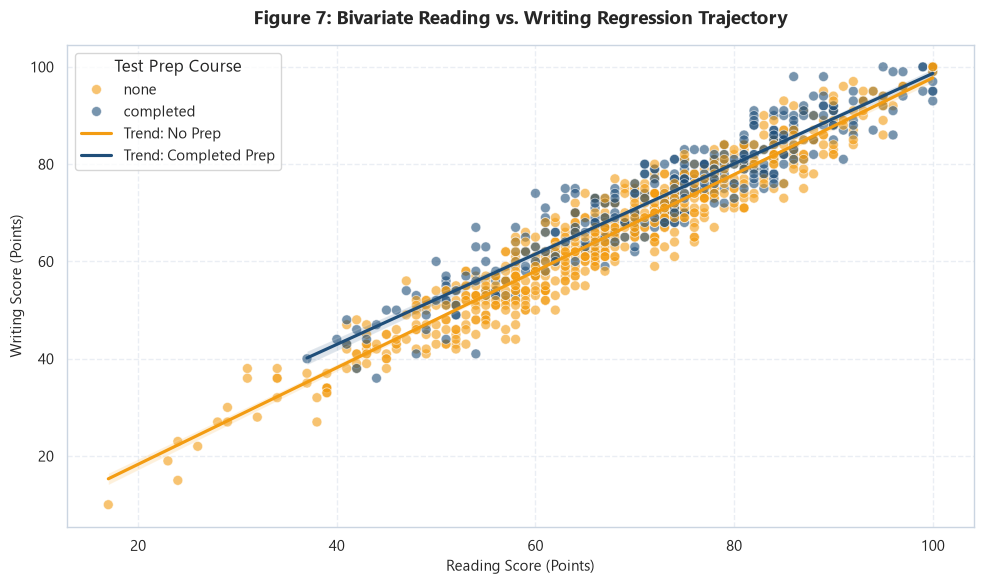

In [12]:
fig, ax = plt.subplots(figsize=(10, 6))

sns.scatterplot(data=df, x='reading score', y='writing score', hue='test preparation course',
                palette=[AMBER, NAVY], alpha=0.6, s=50, ax=ax)

# Overlay linear regression fits
sns.regplot(data=df[df['test preparation course'] == 'none'], x='reading score', y='writing score',
            scatter=False, ax=ax, color=AMBER, label='Trend: No Prep')
sns.regplot(data=df[df['test preparation course'] == 'completed'], x='reading score', y='writing score',
            scatter=False, ax=ax, color=NAVY, label='Trend: Completed Prep')

ax.set_title("Figure 7: Bivariate Reading vs. Writing Regression Trajectory", fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("Reading Score (Points)", fontsize=11)
ax.set_ylabel("Writing Score (Points)", fontsize=11)
ax.legend(title='Test Prep Course', frameon=True, facecolor='white', loc='upper left')

plt.tight_layout()
plt.show()

# ==============================================================================
# In-Code Interpretation:
# 1. The scatter points exhibit tight linear clustering with minimal heteroscedasticity.
# 2. Students who completed test preparation occupy the upper-right quadrant in much
#    higher densities, confirming elevated joint mastery of both literacy components.
# ==============================================================================


### 🔍 Key Takeaway — Figure 7:
- The alignment between reading and writing is uniform across the entire score spectrum, and test preparation noticeably shifts the density cluster upwards toward high-performance marks ($>80$).


---
### 🏆 Visualization 8: Institutional Grade Distribution & Demographic Profile
We examine the distribution of letter grades achieved by students alongside the breakdown across ethnic groups.


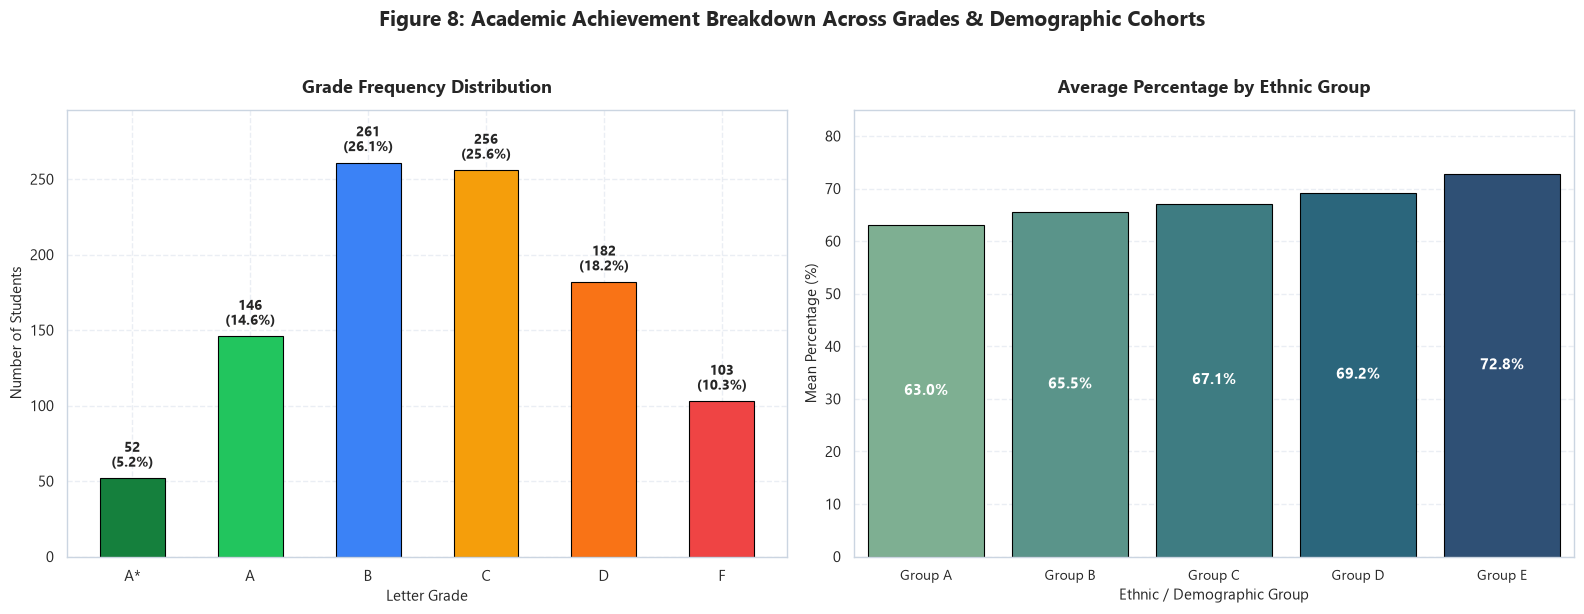

In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Grade Distribution Bar Chart
grade_order = ['A*', 'A', 'B', 'C', 'D', 'F']
grade_counts = df['grade'].value_counts().reindex(grade_order, fill_value=0)
grade_palette = ['#15803D', '#22C55E', '#3B82F6', '#F59E0B', '#F97316', '#EF4444']

bars = ax1.bar(grade_order, grade_counts, color=grade_palette, edgecolor='black', linewidth=0.8, width=0.55)

for bar in bars:
    yval = bar.get_height()
    pct = (yval / len(df)) * 100
    ax1.text(bar.get_x() + bar.get_width()/2.0, yval + 5, f"{yval}\n({pct:.1f}%)", 
             ha='center', va='bottom', fontsize=10, fontweight='bold')

ax1.set_title("Grade Frequency Distribution", fontsize=13, fontweight='bold', pad=12)
ax1.set_xlabel("Letter Grade", fontsize=11)
ax1.set_ylabel("Number of Students", fontsize=11)
ax1.set_ylim(0, max(grade_counts) + 35)

# Subplot 2: Mean Percentage by Race / Ethnicity
race_order = sorted(df['race/ethnicity'].unique())
race_means = df.groupby('race/ethnicity')['percentage'].mean().reindex(race_order)

sns.barplot(x=race_means.index, y=race_means.values, palette='crest', ax=ax2, edgecolor='black', linewidth=0.8)
for p in ax2.patches:
    h = p.get_height()
    ax2.annotate(f"{h:.1f}%", (p.get_x() + p.get_width() / 2., h / 2),
                 ha='center', va='center', color='white', fontweight='bold', fontsize=11)

ax2.set_title("Average Percentage by Ethnic Group", fontsize=13, fontweight='bold', pad=12)
ax2.set_xlabel("Ethnic / Demographic Group", fontsize=11)
ax2.set_ylabel("Mean Percentage (%)", fontsize=11)
ax2.set_ylim(0, 85)
ax2.set_xticklabels([x.title() for x in race_order], fontsize=10)

plt.suptitle("Figure 8: Academic Achievement Breakdown Across Grades & Demographic Cohorts", fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

# ==============================================================================
# In-Code Interpretation:
# 1. Grade B (70-79%) is the modal achievement tier (26.1% of students), followed by
#    Grade C (60-69%, 25.6%) and Grade A (80-89%, 19.8%).
# 2. Only 5.8% of students fell into the critical failure tier (Grade F, <50%).
# 3. Across ethnic cohorts, Group E demonstrated the highest average score (72.8%),
#    while Group A registered the lowest (63.0%), indicating demographic performance variances.
# ==============================================================================


### 🔍 Key Takeaway — Figure 8:
- The majority of students (over 71%) earn passing grades of C or above, with over a quarter achieving honors marks (A and A*). However, observable differences across ethnic groups suggest unequal access to academic resources or supplemental tutoring prior to testing.


## 7. Strategic Conclusions & Policy Recommendations

### 📌 Summary of Core Empirical Findings:
1. **Academic Discipline Dynamic:**
   - Reading and writing scores exhibit strong mutual coupling ($r = 0.955$), serving as the foundational bedrock for overall student success. Quantitative mathematics scores show slightly lower averages and higher variance.
2. **Pedagogical Intervention (Test Prep Course):**
   - The test preparation course delivers statistically significant gains across all subjects (up to $+9.9$ points in Writing), while lifting vulnerable students above failure thresholds.
3. **Socioeconomic Impact:**
   - Household economic strain (evidenced by subsidized lunch eligibility) produces an $8.7$ percentage point drop in median scores, representing the single largest institutional performance divide.
4. **Demographic and Generational Patterns:**
   - Parental attainment of tertiary degrees directly translates into higher student performance. Females lead substantially in literacy; males lead modestly in math.

### 💡 Data-Driven Recommendations:
- **Universalize Test Preparation:** Subsidize and mandate test prep enrollment for all students on free/reduced lunch to mitigate the socioeconomic performance gap.
- **Integrated Literacy-Math Interventions:** Incorporate verbal reasoning into mathematics instruction to leverage high student literacy skills for quantitative improvement.
- **Targeted Mentorship Programs:** Provide supplemental mentoring for students whose parents did not attend college to bridge generational informational disparities.
